# Projet PI² n°156 : modèles de la shortlist sur le dataset v3

**But** : relancer les 4 modèles retenus le 18/11 sur `data/v3`, avec une évaluation honnête, puis les tester sur les
**521 spectres Raman réellement mesurés**. Ce notebook répond aux retours du tuteur du 19/11 : expliquer et comparer
les résultats, classer les données (théorique / expérimental), tester la robustesse sur l'expérimental, figures
avec axes, unités et légendes.

| # | Modèle | Rôle |
|---|---|---|
| 1 | Pics + **XGBoost** | baseline interprétable |
| 2 | **TabPFN** (mêmes features) | modèle « fondation » tabulaire |
| 3 | **CNN 1D**, ensemble de 3 | apprend sur le spectre ; pré-entraîné sur le simulé, appliqué tel quel au réel |
| 4 | **Isolation Forest** | détecter un spectre hors du domaine d'entraînement |
| + | **Prédiction conforme** | ensemble de classes avec garantie de couverture à 95 % |

**Trois protocoles**, toujours affichés côte à côte :
1. *aléatoire* (StratifiedKFold, 3 plis) : mêmes matériaux au train et au test, mesure la mémorisation ;
2. *groupé* (`PredefinedSplit` sur la colonne `fold`) : chaque matériau testé est **inconnu** du modèle, c'est le chiffre à retenir ;
3. *réel* : entraînement sur tout le simulé, test sur les spectres mesurés de Southampton.

Le code réutilisable est dans `src/raman_qc/` ; ce notebook ne fait qu'appeler ces fonctions et tracer.
Durée : environ 15 min sur un CPU 4 cœurs.

In [1]:
# Colab : !git clone https://github.com/manalhdev/raman-2d-qc && %cd raman-2d-qc && !pip install -q xgboost torch tabpfn
import sys, time, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict
from sklearn.neighbors import NearestNeighbors
warnings.filterwarnings("ignore")

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "v3").exists())
sys.path.insert(0, str(RACINE / "src"))
from raman_qc.donnees import charger_v3, catalogue_sources, FAMILLES, COULEURS
from raman_qc.pretraitement import pretraiter, ligne_de_base_als, FENETRES_COMPLETES, PLAGE_COMMUNE_REEL, masque
from raman_qc.features import pics, spectre_par_bandes, noms_pics
from raman_qc.modeles import xgboost, tabpfn, tabpfn_disponible, CNNEnsemble, isolation_forest, Conforme, SEED
from raman_qc.evaluation import comparer, plis_groupes, plis_aleatoires, predictions_hors_pli, scores, taux_tmd_par_source

FIG = RACINE / "resultats" / "shortlist_v3" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 10, "legend.frameon": False})
def sauver(fig, nom): fig.savefig(FIG / f"{nom}.png", bbox_inches="tight")
UA = "Intensité normalisée (u.a.)"; CM = "Décalage Raman (cm⁻¹)"
T0 = time.time(); np.random.seed(SEED)

## 1. Les données : théoriques ou expérimentales ?

In [2]:
X, grid, lab = charger_v3(RACINE)
CV, REEL = (lab.split == "cv").values, (lab.split == "test_reel").values
y, folds, src_reel = lab.y.values, lab.fold.values, lab.source[REEL].values
CAT = catalogue_sources(RACINE); display(CAT)
print(pd.crosstab([lab.type, lab.source], lab.famille, margins=True))
print("\nMatériaux distincts par famille (simulé) :", lab[CV].groupby("famille").groupe.nunique().to_dict())

,categorie,source,contenu,familles,n,usage
0,Théorique - calculé (DFT),Materials Cloud 2024.148 (v1),"Modes Raman calculés par DFT, élargis en spectres","carbone, h-BN, TMD",133,Spectres de référence (base des simulations)
1,Théorique - simulé,"Materials_Cloud_2024.148_augmente (v2/v3, spli...","Spectres DFT + largeur, décalage, bruit, fond,...","carbone, h-BN, TMD",3750,Entraînement et validation croisée groupée
2,Expérimental - brut,Southampton WS2 2018 (DOI 10.5258/SOTON/D0371),"Raman de résonance, 4-295 K, fond de photolumi...",TMD (WS2),289,Test sur réel (le plus difficile)
3,Expérimental - traité par les auteurs,Southampton HS20 + HS57 2021 (DOI 10.5258/SOTO...,"Hétérobicouche MoSe2/WSe2, 4 K, fond déjà sous...",TMD (MoSe2/WSe2),232,Test sur réel
4,Expérimental - positions de pics seulement,Zenodo MoS2 (v1),"Positions E2g / A1g, contrainte, dopage (pas d...",TMD (MoS2),586,Écart théorie / mesure sur les positions de pics


famille                                    TMD  carbone  h-BN   All
type   source                                                      
reel   Southampton_HS20_2021               102        0     0   102
       Southampton_HS57_2021               130        0     0   130
       Southampton_WS2_2018                289        0     0   289
simule Materials_Cloud_2024.148_augmente  1250     1250  1250  3750
All                                       1771     1250  1250  4271

Matériaux distincts par famille (simulé) : {'TMD': 127, 'carbone': 3, 'h-BN': 3}


**Lecture.** Toutes les classes du simulé viennent d'un **seul calcul DFT par matériau** (Materials Cloud), décliné
en 1250 variantes par famille. Le carbone et le h-BN n'ont que **3 matériaux** chacun, les TMD en ont 130 : c'est la
première cause des écarts de performance plus bas. L'expérimental ne contient **que des TMD**, mesurés dans des
conditions très éloignées d'un contrôle qualité de routine (Raman de résonance, 4 à 295 K).

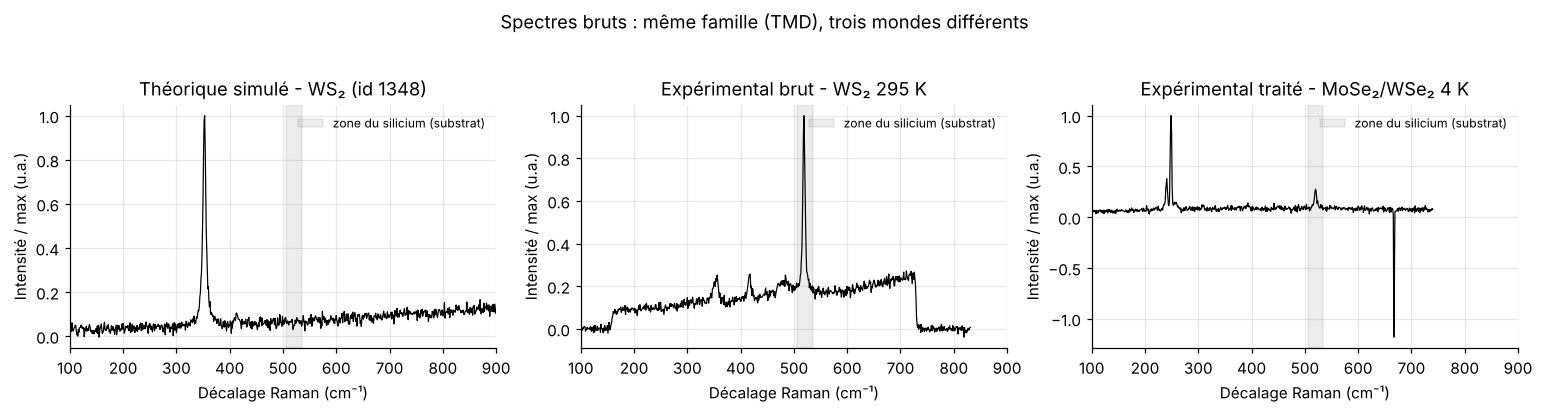

In [3]:
# Un exemple par catégorie : théorique simulé vs expérimental brut vs expérimental traité
ex = {"Théorique simulé - WS₂ (id 1348)": np.where(CV & (lab.id_materials_cloud == 1348))[0][0],
      "Expérimental brut - WS₂ 295 K": np.where(REEL & (lab.source == "Southampton_WS2_2018") & (lab.temperature_K == 295))[0][0],
      "Expérimental traité - MoSe₂/WSe₂ 4 K": np.where(REEL & (lab.source == "Southampton_HS57_2021"))[0][0]}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for a, (t, i) in zip(ax, ex.items()):
    s = X[i]; ok = np.isfinite(s)
    a.plot(grid[ok], s[ok] / np.nanmax(s), color="k", lw=.8)
    a.axvspan(505, 535, color="grey", alpha=.15, label="zone du silicium (substrat)")
    a.set(title=t, xlabel=CM, ylabel="Intensité / max (u.a.)", xlim=(100, 900)); a.legend(loc="upper right", fontsize=8)
fig.suptitle("Spectres bruts : même famille (TMD), trois mondes différents", y=1.03); plt.tight_layout(); sauver(fig, "01_theorique_vs_experimental"); plt.show()

### 1.b Écart théorie / mesure sur les positions de pics
On compare les positions calculées par DFT (Materials Cloud) aux positions **mesurées** : les spectres Southampton
(pics détectés sur le spectre moyen après ligne de base) et les 586 mesures MoS₂ de Zenodo.

In [4]:
modes = pd.read_csv(RACINE / "data/v1/modes_raman_tous.csv")
def modes_dft(i, seuil=50):
    m = modes[(modes.id == i) & (modes.intensite_A4_amu > seuil)]
    return sorted(m.frequence_cm1.round(1).unique())
def pics_moyens(sel, lo=150, hi=450, n=2):
    s = np.nanmean(X[sel], 0); ok = np.isfinite(s) & (grid >= lo) & (grid <= hi)
    s2 = s[ok] - ligne_de_base_als(s[ok][None], lam=1e4)[0]
    from scipy.signal import find_peaks
    pk, pr = find_peaks(s2, prominence=s2.max() * .05)
    return sorted(grid[ok][pk[np.argsort(pr["prominences"])[::-1][:n]]])
zen = pd.read_csv(RACINE / "data/v1/zenodo_MoS2_mesures.csv"); z1 = zen[zen.couche == "1L"]
ECART = pd.DataFrame([
    dict(materiau="WS₂ monocouche", mode="E′ / A₁′", dft=modes_dft(1348)[-2:], mesure=pics_moyens(REEL & (lab.source == "Southampton_WS2_2018") & (lab.temperature_K == 295), 300, 450),
         source_mesure="Southampton 295 K (pics du spectre moyen)"),
    dict(materiau="MoS₂ (DFT : 3R massif, id 2192)", mode="E₂g / A₁g", dft=[363.5, 396.5], mesure=[round(z1.E2g_cm1.mean(), 1), round(z1.A1g_cm1.mean(), 1)],
         source_mesure="Zenodo, 340 points monocouche"),
    dict(materiau="MoSe₂ / WSe₂ (DFT : monocouches id 168 et 291)", mode="A₁′ MoSe₂ / E′+A₁′ WSe₂", dft=[233.3, 237.2], mesure=pics_moyens(REEL & lab.source.str.contains("HS"), 200, 270),
         source_mesure="Southampton HS20+HS57, 4 K"),
])
ECART["ecart_cm1"] = [np.round(np.array(m) - np.array(d), 1).tolist() for d, m in zip(ECART.dft, ECART.mesure)]
ECART["ecart_pct"] = [np.round(100 * (np.array(m) / np.array(d) - 1), 1).tolist() for d, m in zip(ECART.dft, ECART.mesure)]
display(ECART)
print("Rappel : dans le v2/v3, WS₂ id 1348 est RECALÉ (340→356, 403→418) ; les autres TMD ne le sont pas.",
      "Le décalage aléatoire de la simulation est de ±10 cm⁻¹.")

,materiau,mode,dft,mesure,source_mesure,ecart_cm1,ecart_pct
0,WS₂ monocouche,E′ / A₁′,"[339.8, 402.7]","[354.0, 417.0]",Southampton 295 K (pics du spectre moyen),"[14.2, 14.3]","[4.2, 3.6]"
1,"MoS₂ (DFT : 3R massif, id 2192)",E₂g / A₁g,"[363.5, 396.5]","[384.6, 403.8]","Zenodo, 340 points monocouche","[21.1, 7.3]","[5.8, 1.8]"
2,MoSe₂ / WSe₂ (DFT : monocouches id 168 et 291),A₁′ MoSe₂ / E′+A₁′ WSe₂,"[233.3, 237.2]","[240.0, 249.0]","Southampton HS20+HS57, 4 K","[6.7, 11.8]","[2.9, 5.0]"


Rappel : dans le v2/v3, WS₂ id 1348 est RECALÉ (340→356, 403→418) ; les autres TMD ne le sont pas. Le décalage aléatoire de la simulation est de ±10 cm⁻¹.


**À noter sur les spectres réels** (figure ci-dessus) : le WS₂ brut a des marches nettes vers 160 et 730 cm⁻¹
(bords du filtre du spectromètre : hors de cette fenêtre l'intensité est ~0 mais pas NaN), et certains spectres traités
ont des pics négatifs isolés (artefacts ou rayons cosmiques). Ces deux défauts gênent la ligne de base : un
nettoyage (coupure à la vraie plage utile, suppression des pics d'un seul point) est la prochaine amélioration du
prétraitement.

**Lecture.** La DFT sous-estime les fréquences de quelques % (jusqu'à une vingtaine de cm⁻¹ pour MoS₂ E₂g, ce qui est
connu pour la fonctionnelle utilisée). Le WS₂ a été recalé dans le v2, mais pas les autres TMD : une partie de l'écart
théorie / mesure vient de là. Un recalage systématique (facteur d'échelle par famille) est une piste d'amélioration
des données, à valider pic par pic. *Essai fait : étirer tout le simulé de +2 à +6 % fait baisser le score sur le
réel (86 % → 69 %), car le WS₂ est déjà recalé : il faut recaler matériau par matériau, pas globalement.*

## 2. Prétraitement : ligne de base ALS
Lissage Savitzky-Golay (7 points) → ligne de base **ALS** (λ = 10⁵, p = 0,01) → normalisation par le maximum hors
silicium → NaN (hors plage mesurée) à 0. Comparé à la version simple de l'équipe (5ᵉ centile soustrait).

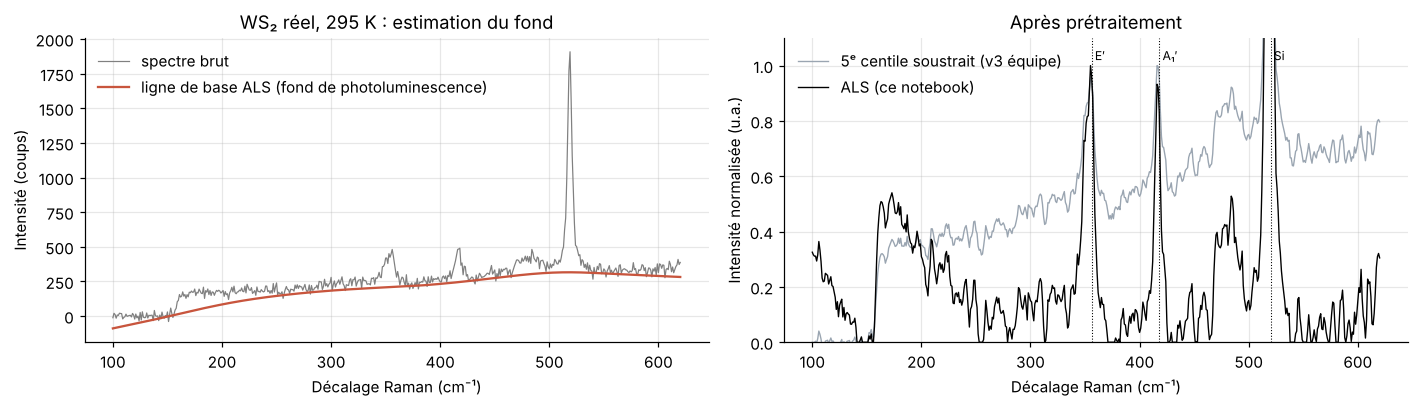

In [5]:
i = ex["Expérimental brut - WS₂ 295 K"]; m = masque(grid, PLAGE_COMMUNE_REEL)
s = X[i, m].astype(float); g = grid[m]; ok = np.isfinite(s)
b = ligne_de_base_als(s[None])[0]
Pc, _ = pretraiter(X[[i]], grid, PLAGE_COMMUNE_REEL, ligne_de_base="centile")
Pa, _ = pretraiter(X[[i]], grid, PLAGE_COMMUNE_REEL, ligne_de_base="als")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(g[ok], s[ok], color="grey", lw=.8, label="spectre brut")
ax[0].plot(g[ok], b[ok], color="#c8553d", lw=1.5, label="ligne de base ALS (fond de photoluminescence)")
ax[0].set(title="WS₂ réel, 295 K : estimation du fond", xlabel=CM, ylabel="Intensité (coups)"); ax[0].legend()
ax[1].plot(g, Pc[0], color="#9aa5b1", lw=.9, label="5ᵉ centile soustrait (v3 équipe)")
ax[1].plot(g, Pa[0], color="k", lw=.9, label="ALS (ce notebook)")
for x0, t in [(356, "E′"), (418, "A₁′"), (520, "Si")]: ax[1].axvline(x0, ls=":", c="k", lw=.7); ax[1].text(x0 + 3, 1.02, t, fontsize=8)
ax[1].set(title="Après prétraitement", xlabel=CM, ylabel=UA, ylim=(0, 1.1)); ax[1].legend(loc="upper left")
plt.tight_layout(); sauver(fig, "02_pretraitement_als"); plt.show()

## 3. Expérience A : simulé, plage complète, aléatoire vs groupé
Plage 100-1800 + 2500-2850 cm⁻¹ (toutes les familles ont leurs pics). Features :
- **pics** : 8 pics les plus proéminents hors silicium (position en cm⁻¹, hauteur, largeur en cm⁻¹) = 24 valeurs ;
- **spectre** : moyenne par bandes de 4 cm⁻¹ = 513 valeurs (XGBoost spectre, CNN, Isolation Forest).

In [6]:
PA, gA = pretraiter(X[CV], grid, FENETRES_COMPLETES, ligne_de_base="als")
FA_pics, FA_spec = pics(PA, gA), spectre_par_bandes(PA, 4)
yA, fA = y[CV], folds[CV]
print("pics :", FA_pics.shape, "| spectre :", FA_spec.shape)
RES, PRED = [], {}
def lancer(nom, fab, F):
    r, p = comparer(nom, fab, F, yA, fA); RES.append(r); PRED[nom] = p
    print(f"{nom:22s} aléatoire {r['aleatoire_accuracy']:.3f} | groupé {r['groupe_accuracy']:.3f} "
          f"(carbone {r['groupe_acc_carbone']:.2f}, h-BN {r['groupe_acc_h-BN']:.2f}, TMD {r['groupe_acc_TMD']:.2f}) | {r['temps_s']} s")
lancer("XGBoost pics", xgboost, FA_pics)
lancer("XGBoost spectre", xgboost, FA_spec)

pics : (3750, 24) | spectre : (3750, 513)


XGBoost pics           aléatoire 0.989 | groupé 0.731 (carbone 0.67, h-BN 0.53, TMD 0.99) | 2.5 s


XGBoost spectre        aléatoire 0.996 | groupé 0.338 (carbone 0.02, h-BN 0.00, TMD 1.00) | 24.6 s


In [7]:
ok, raison = tabpfn_disponible()
if ok:
    lancer("TabPFN pics", tabpfn, FA_pics)
else:
    print("TabPFN NON exécuté ici :", raison)
    print("Pour le lancer : créer un compte Hugging Face, accepter la licence du modèle Prior-Labs/TabPFN-v2-clf,"
          " puis `hf auth login` (ou variable HF_TOKEN), et relancer cette cellule (GPU Colab conseillé).")

TabPFN NON exécuté ici : TabPFNHuggingFaceGatedRepoError: HuggingFace authentication error downloading from 'Prior-Labs/tabpfn_3_5'.
Pour le lancer : créer un compte Hugging Face, accepter la licence du modèle Prior-Labs/TabPFN-v2-clf, puis `hf auth login` (ou variable HF_TOKEN), et relancer cette cellule (GPU Colab conseillé).


In [8]:
CNN = lambda: CNNEnsemble(n_modeles=3, epoques=20)
lancer("CNN 1D ensemble", CNN, FA_spec)

CNN 1D ensemble        aléatoire 0.949 | groupé 0.510 (carbone 0.16, h-BN 0.48, TMD 0.89) | 186.1 s


,aleatoire_accuracy,groupe_accuracy,groupe_f1_macro,groupe_acc_carbone,groupe_acc_h-BN,groupe_acc_TMD,temps_s
modele,,,,,,,
XGBoost pics,98.9%,73.1%,72.1%,67.3%,53.0%,99.0%,2.500000
XGBoost spectre,99.6%,33.8%,19.7%,1.8%,0.0%,99.7%,24.600000
CNN 1D ensemble,94.9%,51.0%,46.2%,16.2%,47.6%,89.2%,186.100000


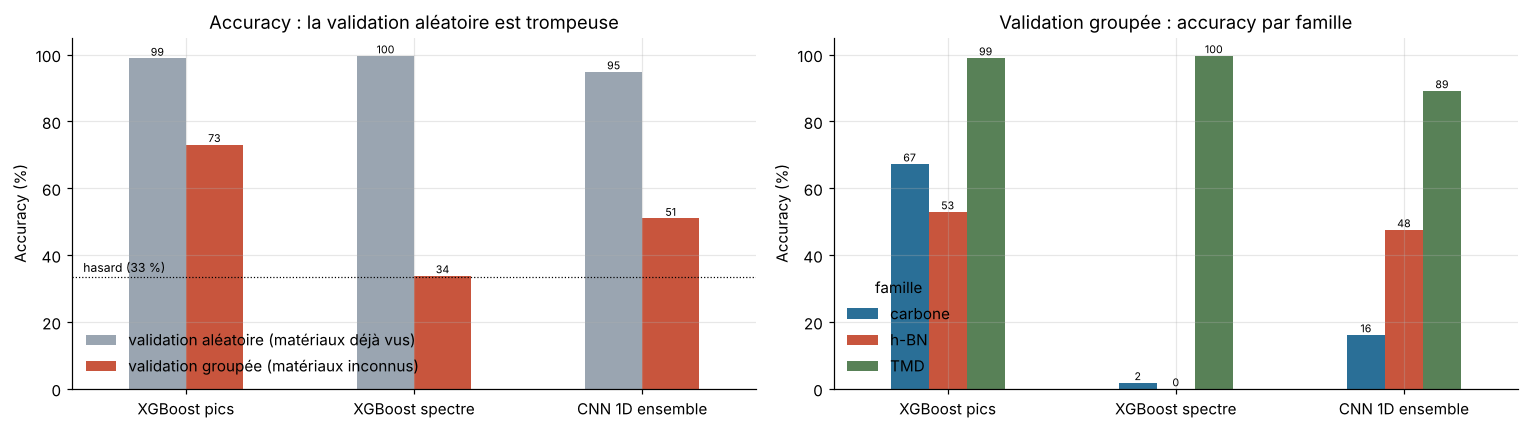

In [9]:
R = pd.DataFrame(RES).set_index("modele")
cols = ["aleatoire_accuracy", "groupe_accuracy", "groupe_f1_macro"] + [f"groupe_acc_{c}" for c in FAMILLES]
display(R[cols + ["temps_s"]].style.format("{:.1%}", subset=cols).background_gradient(cmap="RdYlGn", vmin=0, vmax=1, subset=cols))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
R[["aleatoire_accuracy", "groupe_accuracy"]].rename(columns={"aleatoire_accuracy": "validation aléatoire (matériaux déjà vus)",
    "groupe_accuracy": "validation groupée (matériaux inconnus)"}).mul(100).plot.bar(ax=ax[0], color=["#9aa5b1", "#c8553d"], rot=0)
ax[0].axhline(100 / 3, ls=":", c="k", lw=.8); ax[0].text(-.45, 35, "hasard (33 %)", fontsize=8)
ax[0].set(title="Accuracy : la validation aléatoire est trompeuse", ylabel="Accuracy (%)", xlabel="", ylim=(0, 105)); ax[0].legend(loc="lower left")
R[[f"groupe_acc_{c}" for c in FAMILLES]].set_axis(FAMILLES, axis=1).mul(100).plot.bar(ax=ax[1], color=[COULEURS[c] for c in FAMILLES], rot=0)
ax[1].set(title="Validation groupée : accuracy par famille", ylabel="Accuracy (%)", xlabel="", ylim=(0, 105)); ax[1].legend(title="famille", loc="lower left")
for a in ax:
    for c in a.containers: a.bar_label(c, fmt="%.0f", fontsize=7)
plt.tight_layout(); sauver(fig, "03_aleatoire_vs_groupe"); plt.show()

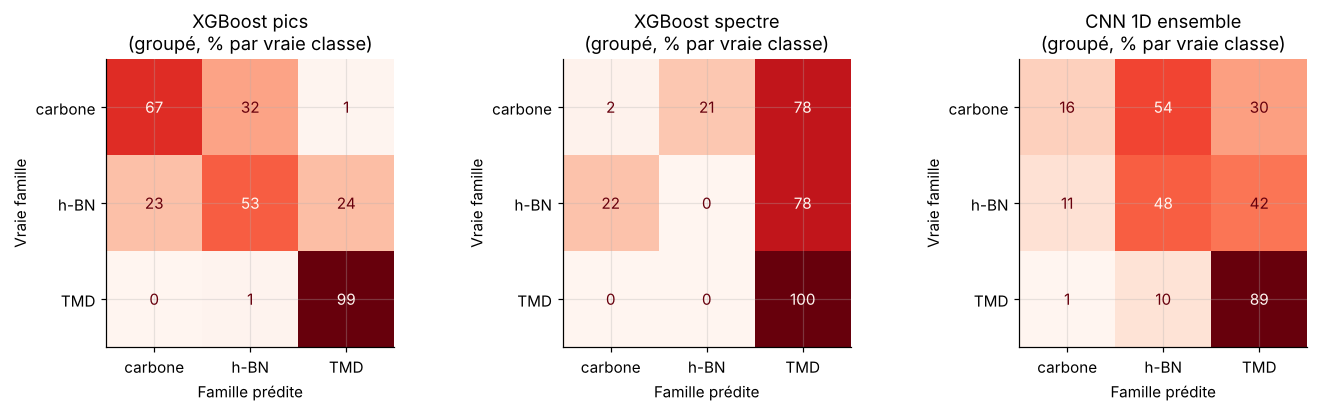

In [10]:
fig, ax = plt.subplots(1, len(PRED), figsize=(4.2 * len(PRED), 3.8))
for a, (nom, p) in zip(np.atleast_1d(ax), PRED.items()):
    ConfusionMatrixDisplay(confusion_matrix(yA, p, normalize="true") * 100, display_labels=FAMILLES).plot(ax=a, colorbar=False, cmap="Reds", values_format=".0f")
    a.set(title=f"{nom}\n(groupé, % par vraie classe)", xlabel="Famille prédite", ylabel="Vraie famille")
plt.tight_layout(); sauver(fig, "04_confusion_groupe"); plt.show()

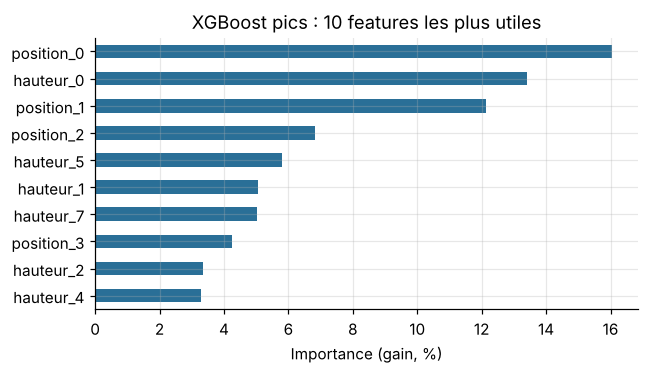

In [11]:
# Ce que regarde XGBoost pics : importance des features (gain)
m_pics = xgboost().fit(FA_pics, yA)
imp = pd.Series(m_pics.feature_importances_, index=noms_pics()).sort_values()[-10:]
fig, ax = plt.subplots(figsize=(6, 3.5)); imp.mul(100).plot.barh(ax=ax, color="#2a6f97")
ax.set(title="XGBoost pics : 10 features les plus utiles", xlabel="Importance (gain, %)", ylabel="")
plt.tight_layout(); sauver(fig, "05_importance_pics"); plt.show()

### Pourquoi de tels écarts ?
On fait varier le **nombre de matériaux TMD vus à l'entraînement** (carbone et h-BN inchangés) et on mesure
l'accuracy groupée sur les TMD : c'est la diversité des matériaux, plus que le nombre de spectres, qui permet de
généraliser.

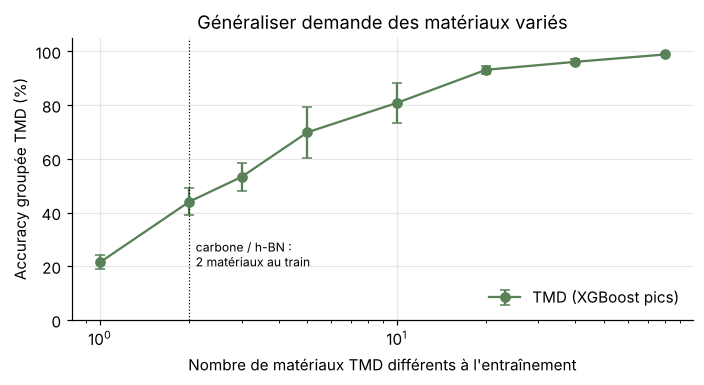

,mean,std
n_materiaux,,
1,0.215,0.026
2,0.441,0.049
3,0.533,0.052
5,0.699,0.095
10,0.808,0.074
20,0.931,0.015
40,0.961,0.009
80,0.988,0.002


In [12]:
rng = np.random.default_rng(SEED); tmd = yA == FAMILLES.index("TMD"); COURBE = []
for k in [1, 2, 3, 5, 10, 20, 40, 80]:
    for rep in range(3):
        acc = []
        for a, b in plis_groupes(fA):
            mats = np.unique(lab.groupe.values[CV][a][tmd[a]]); garde = rng.choice(mats, min(k, len(mats)), replace=False)
            sel = a[~tmd[a] | np.isin(lab.groupe.values[CV][a], garde)]
            p = xgboost().fit(FA_pics[sel], yA[sel]).predict(FA_pics[b])
            acc.append((p[tmd[b]] == yA[b][tmd[b]]).mean())
        COURBE.append(dict(n_materiaux=k, rep=rep, acc_tmd=np.mean(acc)))
COURBE = pd.DataFrame(COURBE).groupby("n_materiaux").acc_tmd.agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.errorbar(COURBE.index, COURBE["mean"] * 100, COURBE["std"] * 100, marker="o", color=COULEURS["TMD"], capsize=3, label="TMD (XGBoost pics)")
ax.axvline(2, ls=":", c="k", lw=.8); ax.text(2.1, 20, "carbone / h-BN :\n2 matériaux au train", fontsize=8)
ax.set(xscale="log", xlabel="Nombre de matériaux TMD différents à l'entraînement", ylabel="Accuracy groupée TMD (%)",
       title="Généraliser demande des matériaux variés", ylim=(0, 105)); ax.legend(loc="lower right")
plt.tight_layout(); sauver(fig, "06_courbe_materiaux"); plt.show(); display(COURBE.round(3))

## 4. Expérience B : test sur les 521 spectres mesurés
Les mesures s'arrêtent vers 600-860 cm⁻¹ : on ré-entraîne sur la **plage commune 100-620 cm⁻¹**. Sur cette plage,
carbone et h-BN n'ont aucun pic (G à 1580, h-BN à 1367) : le test mesure donc surtout « TMD ou pas » ; la bonne
réponse est toujours **TMD**. On croise 3 prétraitements × 3 modèles.

In [13]:
yB, fB = y[CV], folds[CV]; REELS, GAP, MODB = [], [], {}
for bl in ["aucune", "centile", "als"]:
    P, g = pretraiter(X, grid, PLAGE_COMMUNE_REEL, ligne_de_base=bl)
    Fs = {"XGBoost pics": pics(P, g), "XGBoost spectre": spectre_par_bandes(P, 2)}
    for nom, F in Fs.items():
        m = xgboost().fit(F[CV], yB); t = taux_tmd_par_source(m.predict(F[REEL]), src_reel)
        REELS.append(dict(pretraitement=bl, modele=nom, **t.to_dict())); MODB[(bl, nom)] = (m, F)
    # écart de domaine : un classifieur sait-il distinguer simulé et mesuré (TMD seulement) ?
    tm = (lab.famille == "TMD").values; Fs_ = Fs["XGBoost spectre"]
    d = (lab.type[tm] == "reel").values.astype(int)
    pd_ = cross_val_predict(xgboost(), Fs_[tm], d, cv=3, method="predict_proba")[:, 1]
    GAP.append(dict(pretraitement=bl, AUC_simule_vs_reel=roc_auc_score(d, pd_)))
P_als, g_als = pretraiter(X, grid, PLAGE_COMMUNE_REEL, ligne_de_base="als"); FB_spec = spectre_par_bandes(P_als, 2)
cnn_B = CNNEnsemble(n_modeles=3, epoques=20, masque_debut=40).fit(FB_spec[CV], yB)   # pré-entraîné sur le simulé
REELS.append(dict(pretraitement="als", modele="CNN 1D ensemble", **taux_tmd_par_source(cnn_B.predict(FB_spec[REEL]), src_reel).to_dict()))
TR = pd.DataFrame(REELS).set_index(["pretraitement", "modele"])
TR.columns = [c.replace("Southampton_", "").replace("_", " ") for c in TR.columns]
display(TR.style.format("{:.0%}").background_gradient(cmap="RdYlGn", vmin=0, vmax=1)); display(pd.DataFrame(GAP).round(3))

,pretraitement,AUC_simule_vs_reel
0,aucune,0.996
1,centile,0.994
2,als,0.987


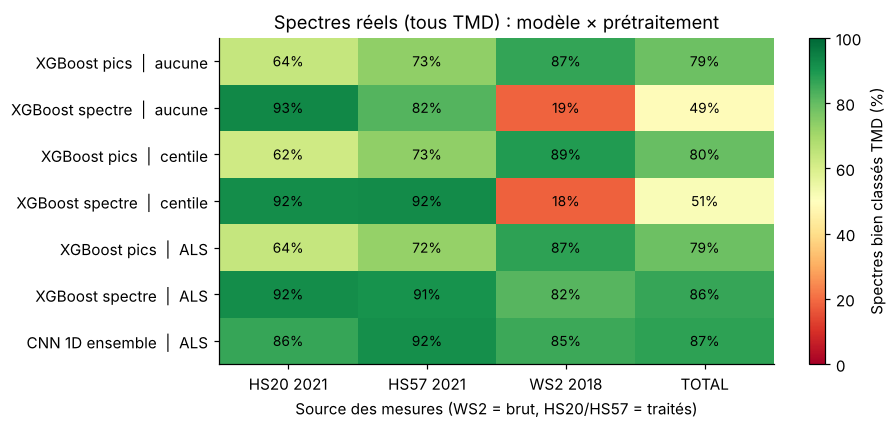

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(TR.values * 100, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(TR.shape[1]), TR.columns); ax.set_yticks(range(len(TR)), [f"{m}  |  {p.upper() if p == 'als' else p}" for p, m in TR.index])
for (r, c), v in np.ndenumerate(TR.values): ax.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=9)
ax.grid(False); plt.colorbar(im, ax=ax, label="Spectres bien classés TMD (%)")
ax.set(title="Spectres réels (tous TMD) : modèle × prétraitement", xlabel="Source des mesures (WS2 = brut, HS20/HS57 = traités)")
plt.tight_layout(); sauver(fig, "07_reel_modele_pretraitement"); plt.show()

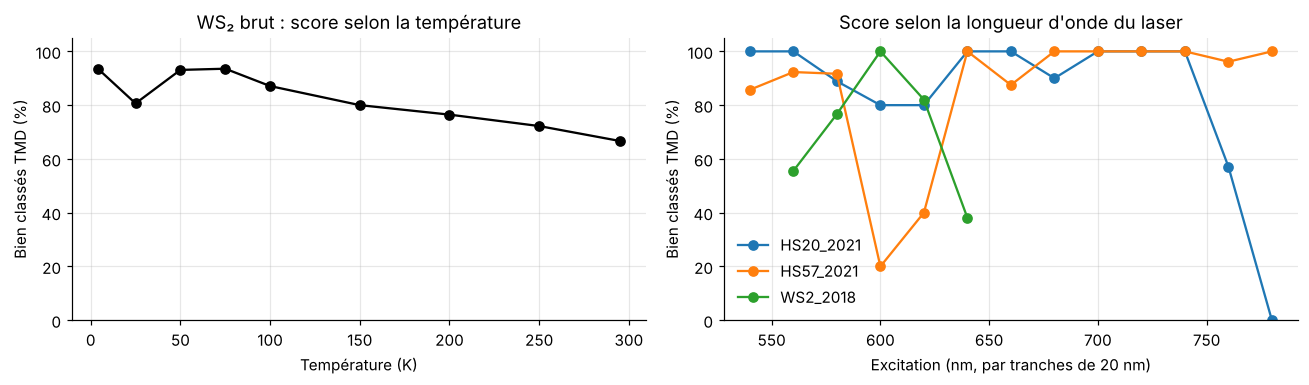

In [15]:
# Robustesse : où se trompe le meilleur modèle ? (température et longueur d'onde du laser, WS₂ brut)
m, F = MODB[("als", "XGBoost spectre")]; ok_reel = m.predict(F[REEL]) == FAMILLES.index("TMD")
L = lab[REEL].assign(ok=ok_reel); ws = L[L.source == "Southampton_WS2_2018"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ws.groupby("temperature_K").ok.mean().mul(100).plot(ax=ax[0], marker="o", color="k")
ax[0].set(title="WS₂ brut : score selon la température", xlabel="Température (K)", ylabel="Bien classés TMD (%)", ylim=(0, 105))
for s_, gdf in L.groupby("source"):
    b_ = gdf.assign(bin=(gdf.excitation_nm // 20) * 20).groupby("bin").ok.mean()
    ax[1].plot(b_.index, b_.values * 100, marker="o", label=s_.replace("Southampton_", ""))
ax[1].set(title="Score selon la longueur d'onde du laser", xlabel="Excitation (nm, par tranches de 20 nm)", ylabel="Bien classés TMD (%)", ylim=(0, 105)); ax[1].legend()
plt.tight_layout(); sauver(fig, "08_robustesse_reel"); plt.show()

## 5. Prédiction conforme : la garantie à 95 % tient-elle ?
XGBoost pics, plage complète. On calibre le seuil de deux façons :
- **calibration aléatoire** : 25 % des spectres d'entraînement tirés au hasard (méthode classique) ;
- **calibration groupée** : un pli de *matériaux* non vus à l'entraînement (proposition de ce notebook).
On teste sur le pli de matériaux inconnus, puis sur le réel (plage courte, XGBoost spectre ALS).

,couverture,taille_moyenne,singletons,vides
methode,,,,
calibration aléatoire,58.6%,0.67,67.5%,32.5%
calibration groupée,91.0%,1.88,41.6%,0.0%
calibration aléatoire → réel,86.6%,1.11,89.3%,0.0%
calibration groupée → réel,87.7%,1.14,87.5%,0.0%


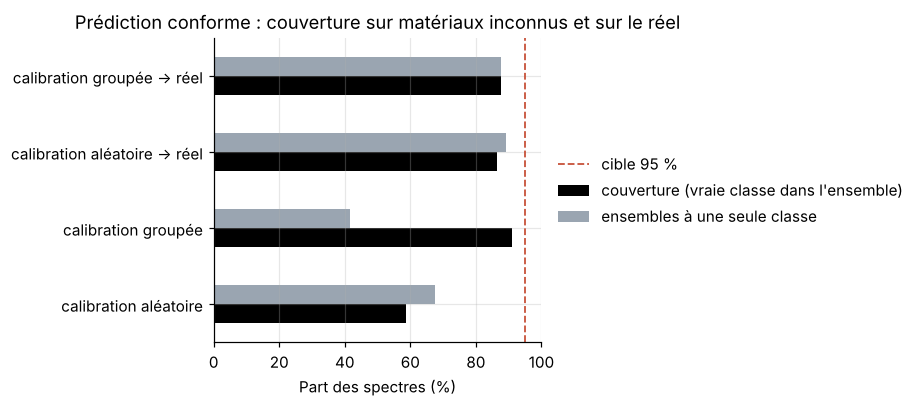

In [16]:
from sklearn.model_selection import train_test_split
CF = []
for test_pli in [0, 1, 2]:
    te = fA == test_pli; cal_pli = (test_pli + 1) % 3
    tr_g, cal_g = (fA != test_pli) & (fA != cal_pli), fA == cal_pli
    idx = np.where(fA != test_pli)[0]; i_tr, i_cal = train_test_split(idx, test_size=.25, random_state=SEED, stratify=yA[idx])
    for nom, (a, c) in {"calibration aléatoire": (i_tr, i_cal), "calibration groupée": (np.where(tr_g)[0], np.where(cal_g)[0])}.items():
        cf = Conforme(xgboost().fit(FA_pics[a], yA[a])).calibrer(FA_pics[c], yA[c])
        CF.append(dict(methode=nom, pli_test=test_pli, **Conforme.resume(cf.ensembles(FA_pics[te]), yA[te])))
CF = pd.DataFrame(CF).groupby("methode").mean(numeric_only=True).drop(columns="pli_test")
# Sur le réel
m_r = xgboost().fit(FB_spec[CV][fB != 2], yB[fB != 2])
for nom, cf in {"calibration aléatoire": None, "calibration groupée": Conforme(m_r).calibrer(FB_spec[CV][fB == 2], yB[fB == 2])}.items():
    if cf is None:
        a, c = train_test_split(np.arange(CV.sum()), test_size=.25, random_state=SEED, stratify=yB)
        cf = Conforme(xgboost().fit(FB_spec[CV][a], yB[a])).calibrer(FB_spec[CV][c], yB[c])
    r = Conforme.resume(cf.ensembles(FB_spec[REEL]), y[REEL]); CF.loc[nom + " → réel"] = r
display(CF.style.format("{:.1%}", subset=["couverture", "singletons", "vides"]).format("{:.2f}", subset=["taille_moyenne"]))
fig, ax = plt.subplots(figsize=(8.5, 3.8))
D = CF[["couverture", "singletons"]].mul(100).rename(columns={"couverture": "couverture (vraie classe dans l'ensemble)", "singletons": "ensembles à une seule classe"})
D.plot.barh(ax=ax, color=["k", "#9aa5b1"])
ax.axvline(95, ls="--", c="#c8553d", lw=1.2, label="cible 95 %")
ax.set(title="Prédiction conforme : couverture sur matériaux inconnus et sur le réel", xlabel="Part des spectres (%)", ylabel="", xlim=(0, 100))
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5)); plt.tight_layout(); sauver(fig, "09_conforme"); plt.show()

## 6. Détection d'anomalies : Isolation Forest vs plus proche voisin
Deux questions :
1. **Matériau d'une famille inconnue** : entraîné sans TMD, les TMD ressortent-ils comme anomalies ? (simulé, plage complète)
2. **Spectre hors domaine** : entraîné sur le simulé TMD, les mesures réelles ressortent-elles ? (plage courte, ALS)
AUC = 1 : séparation parfaite ; 0,5 : hasard.

,question,methode,AUC
0,famille inconnue (TMD),Isolation Forest,0.630
1,famille inconnue (TMD),plus proche voisin (cosinus),1.000
2,mesure réelle (hors domaine),Isolation Forest,0.826
3,mesure réelle (hors domaine),plus proche voisin (cosinus),0.964


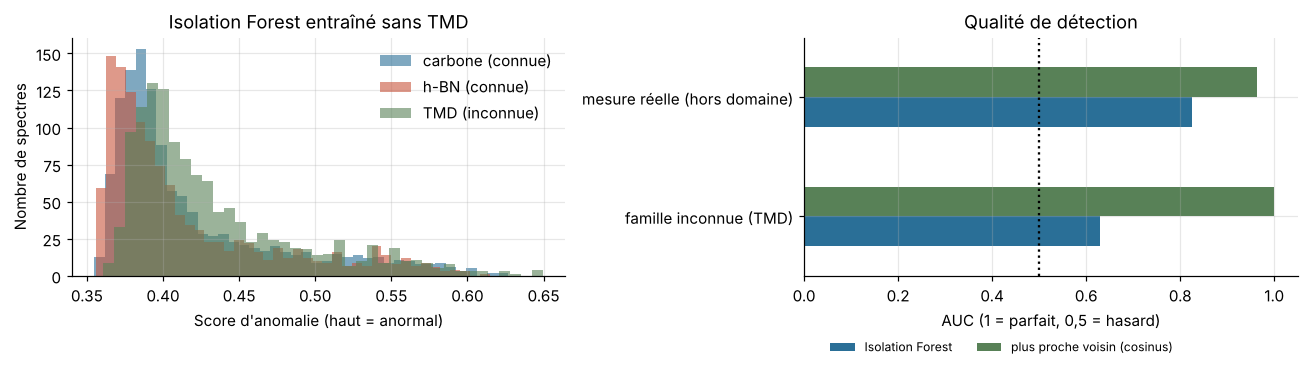

In [17]:
ANO = []
ok_ = yA != FAMILLES.index("TMD"); cible = ~ok_
iso = isolation_forest().fit(FA_spec[ok_]); s_iso = -iso.score_samples(FA_spec)
nn_ = NearestNeighbors(n_neighbors=2, metric="cosine").fit(FA_spec[ok_]); dist = nn_.kneighbors(FA_spec)[0]
s_nn = np.where(ok_, dist[:, 1], dist[:, 0])   # un spectre connu ne compte pas comme son propre voisin
ANO += [dict(question="famille inconnue (TMD)", methode="Isolation Forest", AUC=roc_auc_score(cible, s_iso)),
        dict(question="famille inconnue (TMD)", methode="plus proche voisin (cosinus)", AUC=roc_auc_score(cible, s_nn))]
tmB = CV & (lab.famille == "TMD").values; evalB = (lab.famille == "TMD").values
iso2 = isolation_forest().fit(FB_spec[tmB]); s2 = -iso2.score_samples(FB_spec[evalB]); d2 = REEL[evalB]
nn2 = NearestNeighbors(n_neighbors=2, metric="cosine").fit(FB_spec[tmB]); dd = nn2.kneighbors(FB_spec[evalB])[0]
s2nn = np.where(d2, dd[:, 0], dd[:, 1])
ANO += [dict(question="mesure réelle (hors domaine)", methode="Isolation Forest", AUC=roc_auc_score(d2, s2)),
        dict(question="mesure réelle (hors domaine)", methode="plus proche voisin (cosinus)", AUC=roc_auc_score(d2, s2nn))]
ANO = pd.DataFrame(ANO); display(ANO.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for k, c in enumerate(FAMILLES):
    ax[0].hist(s_iso[yA == k], bins=40, alpha=.6, color=COULEURS[c], label=c + (" (inconnue)" if c == "TMD" else " (connue)"))
ax[0].set(title="Isolation Forest entraîné sans TMD", xlabel="Score d'anomalie (haut = anormal)", ylabel="Nombre de spectres"); ax[0].legend()
ANO.pivot(index="question", columns="methode", values="AUC").plot.barh(ax=ax[1], color=["#2a6f97", "#588157"])
ax[1].axvline(.5, ls=":", c="k"); ax[1].set(title="Qualité de détection", xlabel="AUC (1 = parfait, 0,5 = hasard)", ylabel="", xlim=(0, 1.05)); ax[1].legend(loc="upper center", bbox_to_anchor=(.4, -.22), ncol=2, fontsize=8)
plt.tight_layout(); sauver(fig, "10_anomalies"); plt.show()

## 7. Sauvegarde des résultats

In [18]:
OUT = RACINE / "resultats" / "shortlist_v3"
R.to_csv(OUT / "resultats_simule_aleatoire_vs_groupe.csv"); TR.to_csv(OUT / "resultats_reel.csv")
CF.to_csv(OUT / "resultats_conforme.csv"); ANO.to_csv(OUT / "resultats_anomalies.csv", index=False)
ECART.to_csv(OUT / "ecart_theorie_mesure.csv", index=False); CAT.to_csv(OUT / "catalogue_donnees.csv", index=False)
pd.DataFrame(GAP).to_csv(OUT / "ecart_domaine_auc.csv", index=False); COURBE.to_csv(OUT / "courbe_nb_materiaux.csv")
print(sorted(p.name for p in OUT.iterdir())); print("Durée totale :", round((time.time() - T0) / 60, 1), "min")

['catalogue_donnees.csv', 'courbe_nb_materiaux.csv', 'ecart_domaine_auc.csv', 'ecart_theorie_mesure.csv', 'figures', 'resultats_anomalies.csv', 'resultats_conforme.csv', 'resultats_reel.csv', 'resultats_simule_aleatoire_vs_groupe.csv']
Durée totale : 5.4 min


## 8. Conclusions

**Résultats clés (à reprendre dans le rapport)**

| Question | Résultat | Explication |
|---|---|---|
| Quel modèle sur matériaux inconnus ? | **XGBoost pics : 73 %** groupé (99 % aléatoire) ; CNN 51 % ; XGBoost spectre 34 % | Les positions / largeurs de pics sont des grandeurs physiques qui se transfèrent d'un matériau à l'autre ; le spectre brut fait apprendre « par cœur » les 3 matériaux de carbone et de h-BN. |
| Pourquoi carbone et h-BN échouent ? | 67 % et 53 % au mieux, contre 99 % pour les TMD | Seulement 2 matériaux au train par pli. La courbe du § 3 montre qu'il faut ~20 matériaux par famille pour dépasser 90 %. **C'est un problème de données, pas de modèle.** |
| Aléatoire ou groupé ? | Écart de 25 à 65 points | La validation aléatoire mesure la mémorisation ; seul le chiffre groupé dit ce qui se passera sur un nouvel échantillon. |
| Théorique vs expérimental | DFT 2 à 6 % sous les fréquences mesurées ; un classifieur sépare simulé et réel avec AUC 0,99 | Raman de résonance, basse température, fond de photoluminescence, bords de filtre : les mesures Southampton sont très loin du simulé. |
| Réel (521 TMD mesurés) | **CNN 1D + ALS : 87 %**, XGBoost spectre + ALS : 86 % ; sans ALS le WS₂ brut tombe à 19 % | La ligne de base ALS enlève le fond de photoluminescence : c'est l'étape la plus rentable du pipeline. |
| Robustesse | WS₂ : 93 % à 4-75 K, 67 % à 295 K ; quelques longueurs d'onde laser ratées (HS57 vers 600 nm, HS20 à 780 nm) | Les pics de résonance changent d'intensité relative selon le laser : il faudrait des spectres simulés « en résonance » ou des vraies mesures à 532 nm. |
| Prédiction conforme | Calibration aléatoire : 59 % de couverture sur matériaux inconnus ; **calibration groupée : 91 %** ; réel : 88 % | Calibrer sur des *matériaux* non vus rend la garantie presque tenue (prix : ensembles plus gros, 1,9 classe en moyenne). |
| Anomalies | Isolation Forest AUC 0,63 (famille inconnue) / 0,83 (mesure réelle) ; plus proche voisin cosinus 1,00 / 0,96 | Pour signaler « je n'ai jamais vu ce spectre », la distance au plus proche voisin est bien meilleure que l'Isolation Forest. |
| TabPFN | Non exécuté ici (modèle soumis à licence sur Hugging Face) | Cellule prête : accepter la licence, `hf auth login`, relancer sur Colab. |

**Prochaines étapes proposées**
1. Données : ajouter des matériaux de carbone et de h-BN (et de vrais spectres de graphène / h-BN à 532 nm) ; recaler les TMD matériau par matériau.
2. Prétraitement : couper chaque spectre réel à sa vraie plage utile, supprimer les pics d'un point (rayons cosmiques).
3. Modèles : garder XGBoost pics comme référence, CNN + ALS pour le réel, conforme calibré par matériau, détection hors domaine par plus proche voisin.
4. Démo : `python -m raman_qc.pipeline analyser spectre.csv` donne la famille, l'ensemble conforme 95 % et une alerte hors domaine.